# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

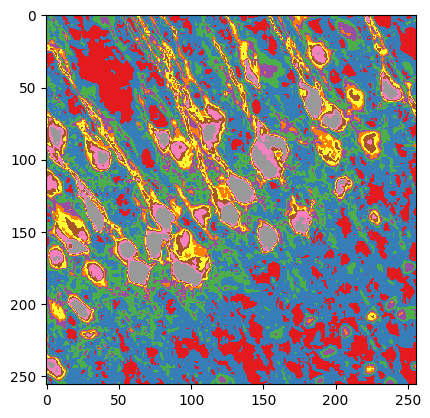

In [17]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'Set1')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [9]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

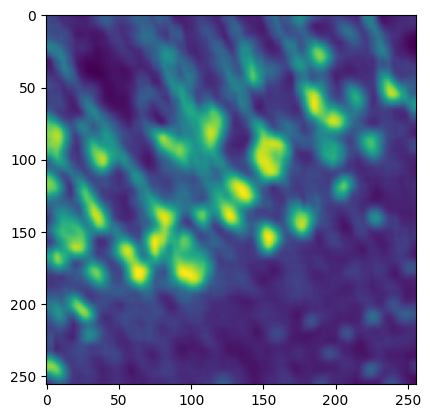

In [10]:
img_PSFU = conv(img, psf, mode = "same", boundary = "symm")
plt.imshow(img_PSFU)

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

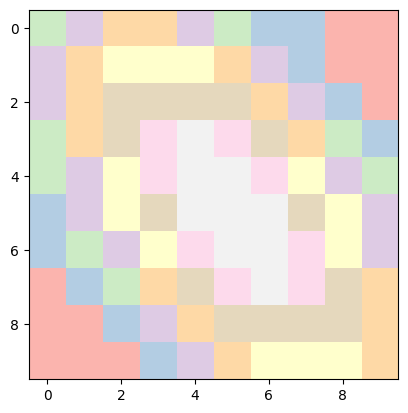

In [15]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'Pastel1')

Apply the second psf to the image:

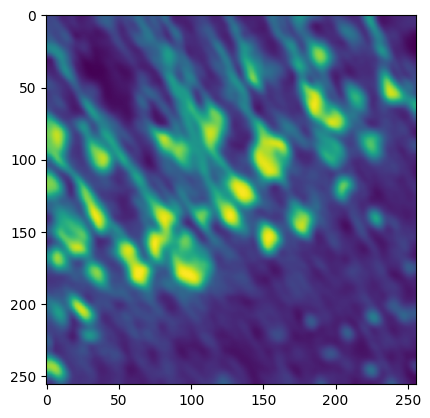

In [27]:
gpsf = create_psf(psf_size)
img_PSFG = conv(img, gpsf, mode = "same", boundary = "symm")
plt.imshow(img_PSFG)

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [86]:
def r_l_deconvolution(img, psf, n_iterations):
    img_deconv = np.full(img.shape, 0.5)
    h = img_deconv

    g = img

    p = psf

    p_star = np.flip(p)

    for i in range (n_iterations):
        h = h*(conv((g / (conv(h, p, mode = "same", boundary = "symm")+1e-10)), p_star, mode = "same", boundary = "symm"))
        
    h = h.clip(0,1)
    return h

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [103]:
deconv_img = r_l_deconvolution(img, gpsf, 20)

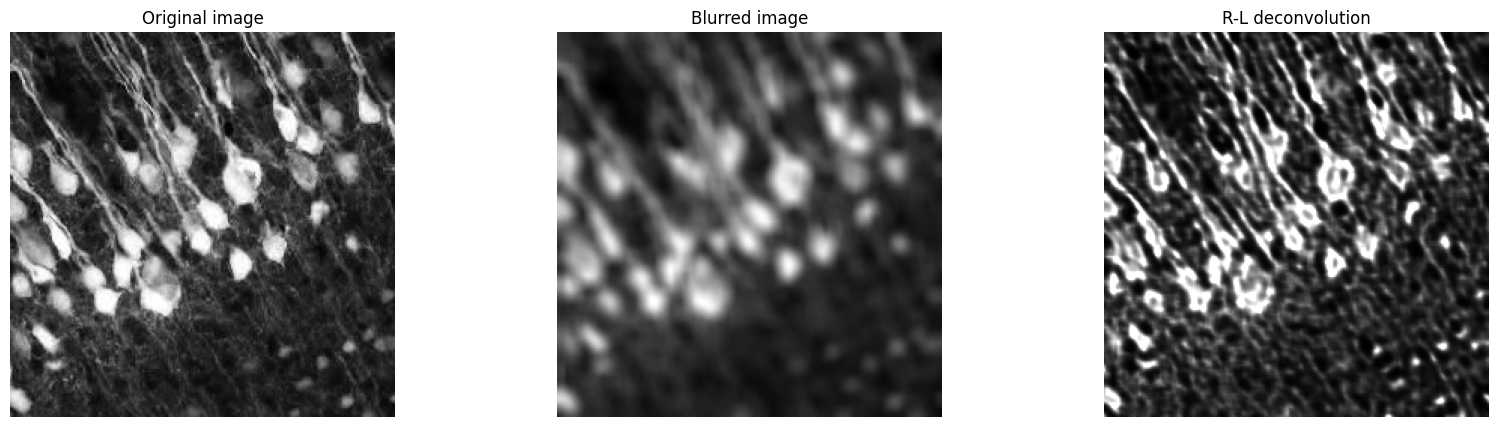

In [104]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_PSFU, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [ ]:
noise = (np.random.normal(loc=0,size=img_blurred.shape))
reduce_factor = 5
noise = noise / reduce_factor

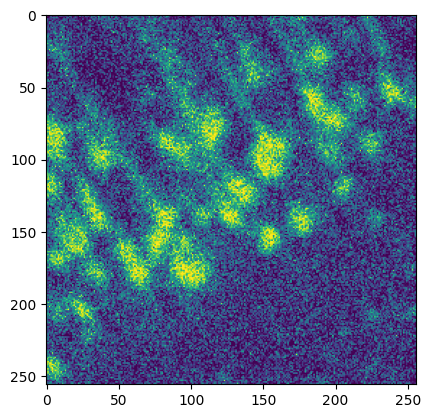

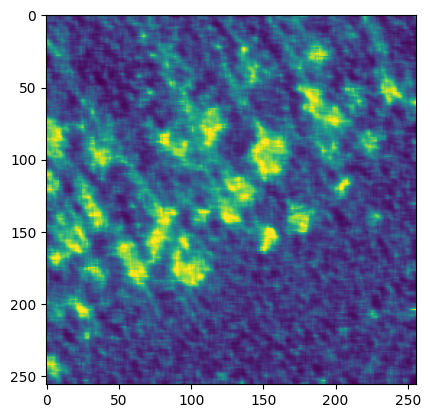

In [110]:
img_blurred = img_PSFU
img_blurred_noise = img_blurred + noise
img_blurred_noise = img_blurred_noise.clip(0,1)
plt.figure()
plt.imshow(img_blurred_noise)

noise_deconv = r_l_deconvolution(img_blurred_noise, gpsf, 10)
plt.figure()
plt.imshow(noise_deconv)

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

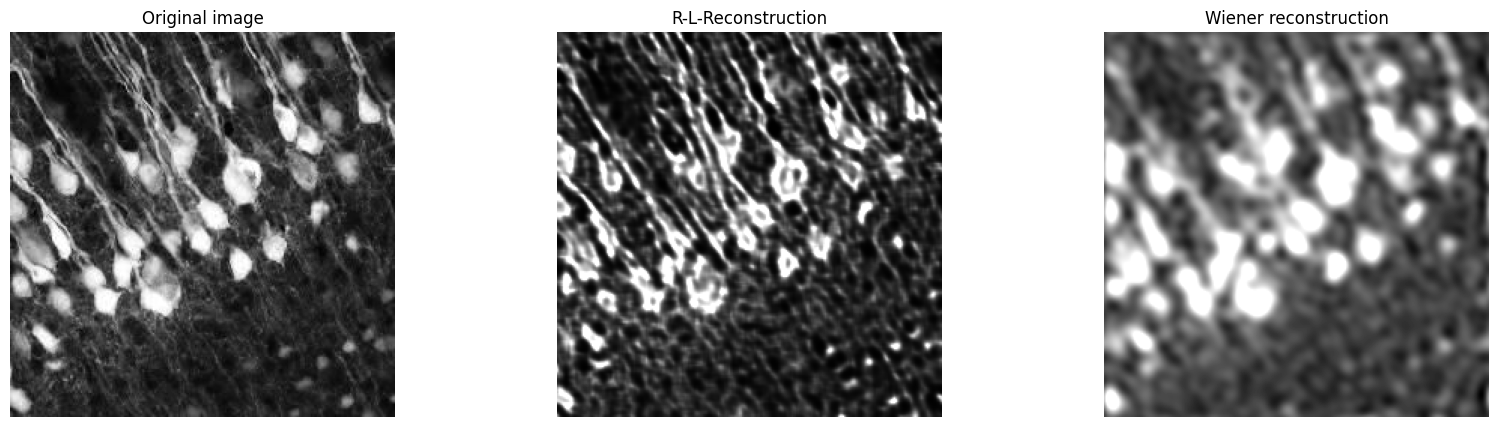

In [112]:
noise_wiener = wiener(img_blurred_noise, gpsf, balance = 2, clip = True)


plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L-Reconstruction')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(noise_wiener, 'gray')
plt.title('Wiener reconstruction')
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

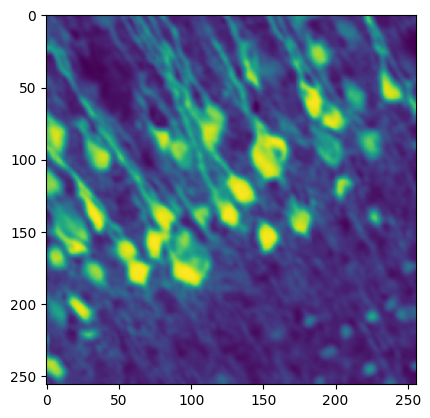

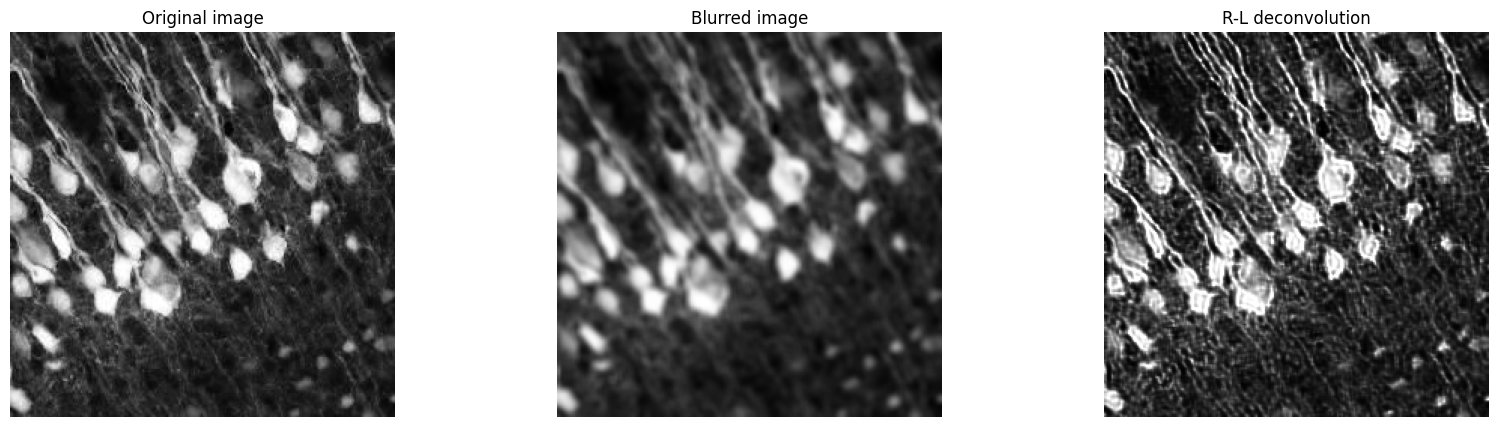

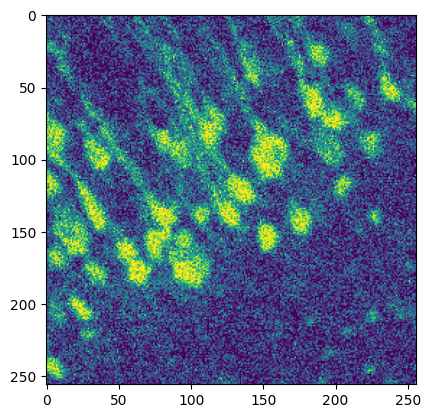

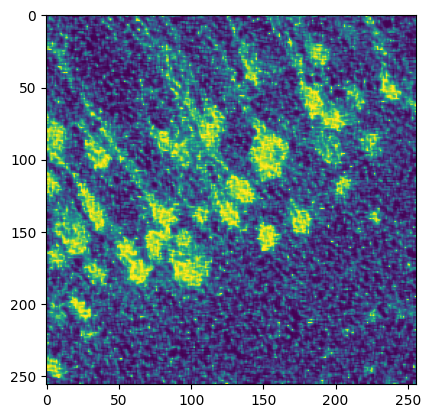

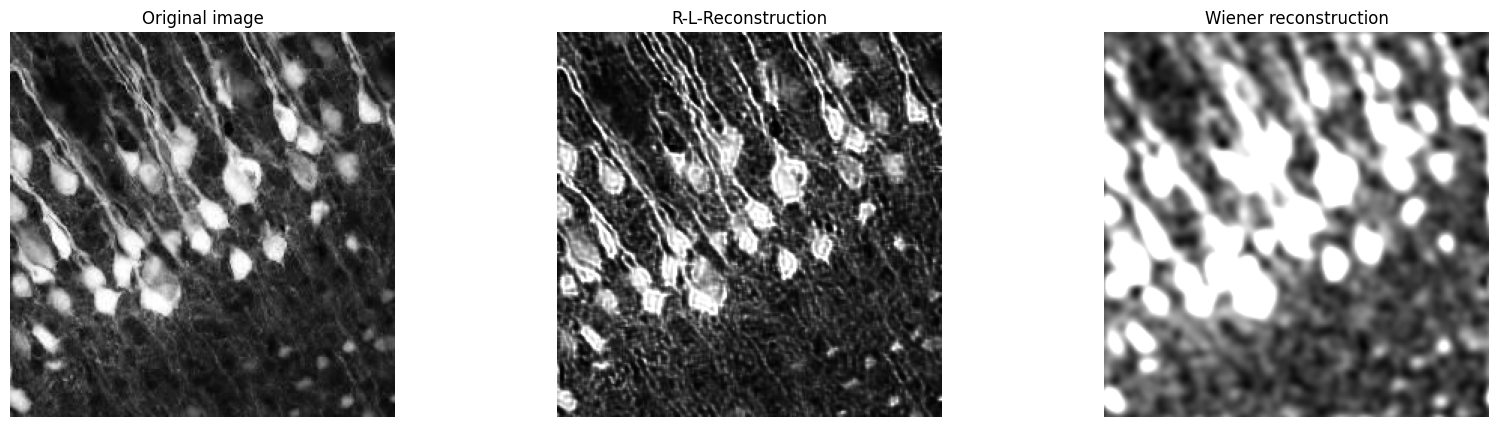

In [113]:
psf_size = 5
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

img_PSFU = conv(img, psf, mode = "same", boundary = "symm")
plt.imshow(img_PSFU)

gpsf = create_psf(psf_size)
img_PSFG = conv(img, gpsf, mode = "same", boundary = "symm")
plt.imshow(img_PSFG)

deconv_img = r_l_deconvolution(img, gpsf, 20)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_PSFU, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

noise = (np.random.normal(loc=0,size=img_blurred.shape))
reduce_factor = 5
noise = noise / reduce_factor

img_blurred = img_PSFU
img_blurred_noise = img_blurred + noise
img_blurred_noise = img_blurred_noise.clip(0,1)
plt.figure()
plt.imshow(img_blurred_noise)

noise_deconv = r_l_deconvolution(img_blurred_noise, gpsf, 10)
plt.figure()
plt.imshow(noise_deconv)

noise_wiener = wiener(img_blurred_noise, gpsf, balance = 2, clip = True)


plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L-Reconstruction')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(noise_wiener, 'gray')
plt.title('Wiener reconstruction')
plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

Text(0.5, 1.0, 'Uniform')

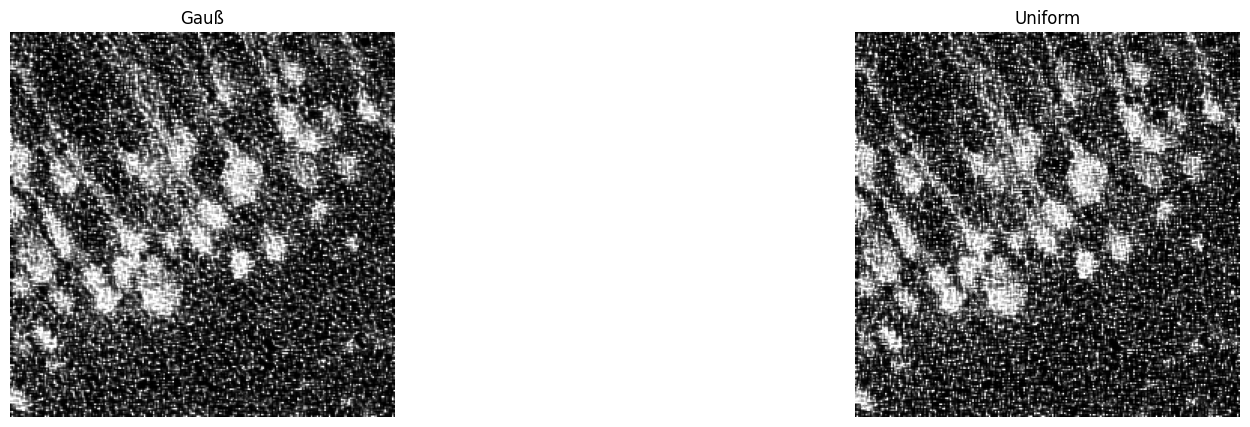

In [114]:
deconv_g = r_l_deconvolution(img_blurred_noise, gpsf, 20)
deconv_u = r_l_deconvolution(img_blurred_noise, psf, 20)

plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(deconv_g, 'gray')
plt.title('Gauß')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(deconv_u, 'gray')
plt.title('Uniform')

